# 05 — Un modèle profond : LSTM

Le réflexe « série temporelle + deep learning » mène au LSTM. Je le teste honnêtement :
petit réseau, fenêtre d'un an en entrée, entraînement avec arrêt anticipé. La question
n'est pas de sortir l'architecture parfaite mais de voir s'il justifie sa complexité face
à SARIMA.

In [1]:
import sys, warnings, os
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
os.environ["KERAS_BACKEND"] = "torch"
import keras
from src import preprocessing, models, plotting
print("backend keras :", keras.backend.backend())
s = preprocessing.serie_hebdo(3, "PAY").dropna()

backend keras : torch


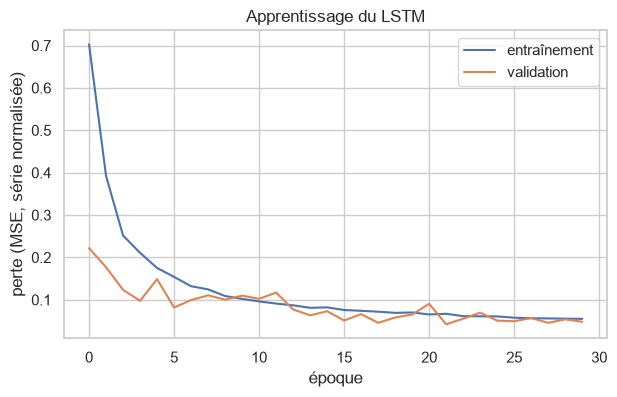

In [2]:
coupe = "2019-07-01"
train = s.loc[:coupe]

lstm = models.LSTMForecaster(fenetre=52, units=32, epochs=80)
lstm.fit(train)
hist = lstm.model_.history.history
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(hist["loss"], label="entraînement")
ax.plot(hist["val_loss"], label="validation")
ax.set(xlabel="époque", ylabel="perte (MSE, série normalisée)", title="Apprentissage du LSTM")
ax.legend()
plotting.save(fig, "05_lstm_apprentissage")
plt.show()

In [3]:
# Prévision glissante t+1 et t+4 sur la période de test (mise à jour sans ré-entraînement,
# le ré-entraînement complet à chaque semaine serait trop coûteux — c'est une limite assumée).
from src import backtest
r_lstm = backtest.rolling_origin(lambda: models.LSTMForecaster(fenetre=52, units=32, epochs=80),
                                 s, debut_test=coupe, horizons=(1, 4), pas=4, refit_every=10_000)
sc_lstm = backtest.scores(r_lstm).drop(columns="RMSE")
sc_lstm.index = [f"+{h} sem." for h in sc_lstm.index]
sc_lstm.round(2)

,MAE
+1 sem.,18.90
+4 sem.,92.79


In [4]:
# Repère SARIMA sur exactement la même grille d'origines.
r_sar = backtest.rolling_origin(models.Sarima, s, debut_test=coupe, horizons=(1, 4),
                                pas=4, refit_every=26)
sc_sar = backtest.scores(r_sar).drop(columns="RMSE"); sc_sar.index = sc_lstm.index
pd.concat({"LSTM": sc_lstm["MAE"], "SARIMA": sc_sar["MAE"]}, axis=1).round(2)

,LSTM,SARIMA
+1 sem.,18.90,11.45
+4 sem.,92.79,42.18


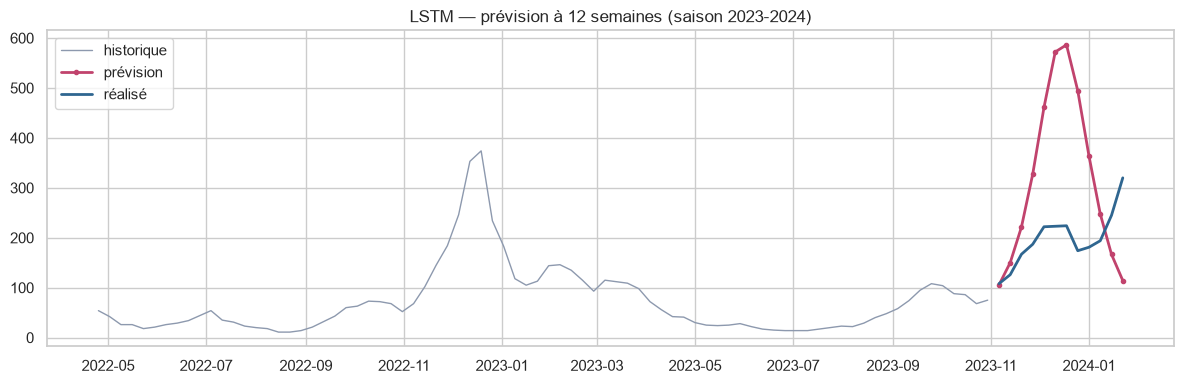

In [5]:
# Une prévision LSTM illustrée sur une saison.
lstm.update(s.loc[:"2023-11-01"])
f = lstm.forecast(12)
fig = plotting.prevision(s.loc[:"2023-11-01"], f, reel=s, titre="LSTM — prévision à 12 semaines (saison 2023-2024)")
plotting.save(fig, "05_lstm_exemple")
plt.show()

Verdict : le LSTM **fait nettement moins bien que SARIMA**. MAE ~19 contre ~11 à 1 semaine, et il décroche complètement à 4 semaines (la prévision récursive d'un réseau non contraint diverge vite). Sur ~1 500 points hebdomadaires univariés, il n'a pas assez de matière pour rivaliser avec un modèle statistique bien posé, et il coûte beaucoup plus cher à entraîner.

Ça ne condamne pas l'approche dans l'absolu : avec les 13 régions en parallèle, des variables exogènes et un entraînement multi-horizon (une sortie par horizon plutôt qu'une récursion), un modèle séquentiel pourrait reprendre la main. En l'état, pour prévoir la grippe nationale à court terme, SARIMA reste le bon choix.